In [1]:
import tensorflow as tf

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3280s 19us/step
(50000, 32, 32, 3)
(50000, 1)
(10000, 32, 32, 3)
(10000, 1)


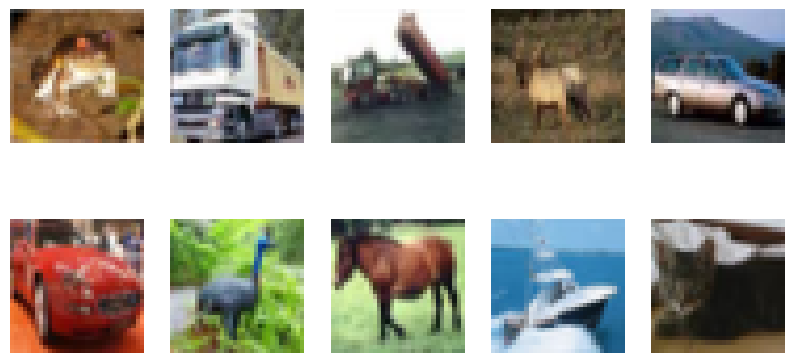

In [2]:
import matplotlib.pyplot as plt

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Display 10 images
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.axis("off")

plt.show()

In [3]:
# Flatten CIFAR-10 images

x_train_flat = x_train.reshape(x_train.shape[0], -1)
x_test_flat = x_test.reshape(x_test.shape[0], -1)

print("Training shape:", x_train_flat.shape)
print("Test shape:", x_test_flat.shape)

Training shape: (50000, 3072)
Test shape: (10000, 3072)


In [4]:
print("First 10 labels:")
print(y_train[:10].flatten())

print("Number of classes:", len(set(y_train.flatten())))

First 10 labels:
[6 9 9 4 1 1 2 7 8 3]
Number of classes: 10


In [5]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(256, activation='relu', input_shape=(3072,)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 820,874 (3.13 MB)

 Trainable params: 820,874 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

model = Sequential([
    Input(shape=(3072,)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 820,874 (3.13 MB)

 Trainable params: 820,874 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [8]:
history = model.fit(
    x_train_flat,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.3211 - loss: 1.8791 - val_accuracy: 0.3638 - val_loss: 1.7599
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3910 - loss: 1.7047 - val_accuracy: 0.4098 - val_loss: 1.6734
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4196 - loss: 1.6360 - val_accuracy: 0.4076 - val_loss: 1.6489
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4385 - loss: 1.5745 - val_accuracy: 0.4384 - val_loss: 1.5693
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4509 - loss: 1.5359 - val_accuracy: 0.4344 - val_loss: 1.5723


In [9]:
test_loss, test_accuracy = model.evaluate(
    x_test_flat,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4349 - loss: 1.5602
Test Loss: 1.5601638555526733
Test Accuracy: 0.4348999857902527
Test Accuracy (%): 43.48999857902527


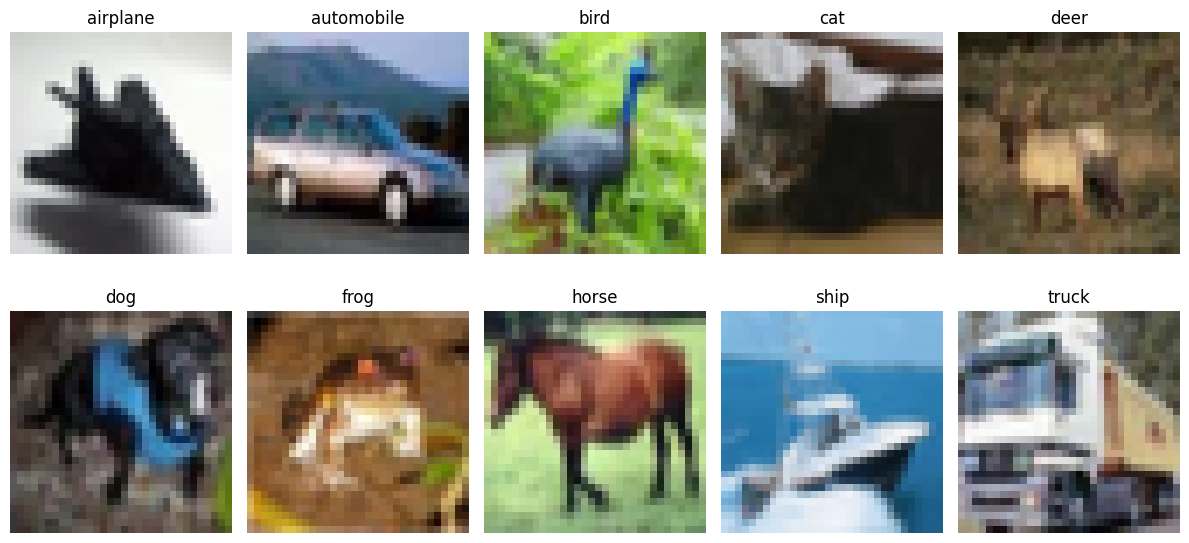

In [10]:
import matplotlib.pyplot as plt

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

plt.figure(figsize=(12, 6))

for class_id in range(10):
    # Find the first image belonging to this class
    index = (y_train.flatten() == class_id).nonzero()[0][0]

    plt.subplot(2, 5, class_id + 1)
    plt.imshow(x_train[index])
    plt.title(class_names[class_id])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
import numpy as np

class NeuralNetwork:
    def __init__(self, input_size, hidden_layers, output_size):
        self.layer_sizes = [input_size] + hidden_layers + [output_size]
        self.weights = []
        self.biases = []

        # Initialize weights and biases
        for i in range(len(self.layer_sizes) - 1):
            w = np.random.randn(
                self.layer_sizes[i],
                self.layer_sizes[i + 1]
            ) * 0.01

            b = np.zeros((1, self.layer_sizes[i + 1]))

            self.weights.append(w)
            self.biases.append(b)

    def forward(self, X):
        A = X

        for i in range(len(self.weights) - 1):
            Z = np.dot(A, self.weights[i]) + self.biases[i]
            A = np.maximum(0, Z)   # ReLU

        # Output layer
        Z = np.dot(A, self.weights[-1]) + self.biases[-1]

        # Softmax
        Z = Z - np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z)
        output = exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

        return output

In [12]:
input_size = 3072
hidden_layers = [256, 128]
output_size = 10

network = NeuralNetwork(
    input_size,
    hidden_layers,
    output_size
)

print("Layer sizes:", network.layer_sizes)

Layer sizes: [3072, 256, 128, 10]


In [13]:
sample_output = network.forward(x_train_flat[:5])

print("Output shape:", sample_output.shape)
print("Output probabilities:")
print(sample_output)
print("Probability sums:")
print(np.sum(sample_output, axis=1))

Output shape: (5, 10)
Output probabilities:
[[0.10009431 0.09978064 0.10013674 0.10019036 0.09998408 0.10033132
  0.0997649  0.10012272 0.10004975 0.09954518]
 [0.09994128 0.09977044 0.10022684 0.10022448 0.09996997 0.1003827
  0.09984641 0.09999923 0.10000486 0.09963378]
 [0.09979175 0.09997323 0.10021288 0.10008017 0.09980486 0.10032852
  0.09980336 0.1001873  0.09988489 0.09993304]
 [0.09999648 0.09990127 0.10016609 0.10013568 0.09996836 0.10026037
  0.09979792 0.10007744 0.10000147 0.09969492]
 [0.0999933  0.09969667 0.10037481 0.1000688  0.09991001 0.10021375
  0.09984264 0.10012199 0.10008663 0.09969141]]
Probability sums:
[1. 1. 1. 1. 1.]


In [14]:
import numpy as np

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


def cross_entropy_loss(y_true, y_pred):
    m = y_true.shape[0]

    # Convert labels to one-hot
    y_one_hot = np.zeros_like(y_pred)
    y_one_hot[np.arange(m), y_true] = 1

    # Avoid log(0)
    y_pred = np.clip(y_pred, 1e-12, 1.0)

    loss = -np.sum(y_one_hot * np.log(y_pred)) / m

    return loss

In [15]:
def backward(network, X, y):
    m = X.shape[0]

    activations = [X]
    pre_activations = []

    # Forward pass while storing values needed for backpropagation
    A = X

    for i in range(len(network.weights) - 1):
        Z = np.dot(A, network.weights[i]) + network.biases[i]
        A = np.maximum(0, Z)  # ReLU

        pre_activations.append(Z)
        activations.append(A)

    # Output layer
    Z = np.dot(A, network.weights[-1]) + network.biases[-1]
    Y_hat = softmax(Z)

    pre_activations.append(Z)
    activations.append(Y_hat)

    # One-hot encoding
    y_one_hot = np.zeros_like(Y_hat)
    y_one_hot[np.arange(m), y] = 1

    # Output gradient
    dZ = (Y_hat - y_one_hot) / m

    dW = [None] * len(network.weights)
    db = [None] * len(network.biases)

    # Backpropagate
    for i in reversed(range(len(network.weights))):

        dW[i] = np.dot(activations[i].T, dZ)
        db[i] = np.sum(dZ, axis=0, keepdims=True)

        if i > 0:
            dA = np.dot(dZ, network.weights[i].T)

            # ReLU derivative
            dZ = dA * (pre_activations[i - 1] > 0)

    return dW, db, Y_hat

In [16]:
X_batch = x_train_flat[:64]
y_batch = y_train[:64].flatten()

dW, db, predictions = backward(
    network,
    X_batch,
    y_batch
)

print("Prediction shape:", predictions.shape)

for i in range(len(dW)):
    print(f"Layer {i+1} weight gradient shape:", dW[i].shape)
    print(f"Layer {i+1} bias gradient shape:", db[i].shape)

Prediction shape: (64, 10)
Layer 1 weight gradient shape: (3072, 256)
Layer 1 bias gradient shape: (1, 256)
Layer 2 weight gradient shape: (256, 128)
Layer 2 bias gradient shape: (1, 128)
Layer 3 weight gradient shape: (128, 10)
Layer 3 bias gradient shape: (1, 10)


In [17]:
def sgd_update(network, dW, db, learning_rate=0.01):
    for i in range(len(network.weights)):
        network.weights[i] -= learning_rate * dW[i]
        network.biases[i] -= learning_rate * db[i]

In [18]:
# Save the current weight before update
old_weight = network.weights[0].copy()

# Apply SGD update
sgd_update(network, dW, db, learning_rate=0.01)

# Check whether weights changed
weight_change = np.mean(np.abs(network.weights[0] - old_weight))

print("Average weight change:", weight_change)

Average weight change: 2.353535022979219e-07


In [19]:
def initialize_momentum(network):
    velocity_w = [np.zeros_like(w) for w in network.weights]
    velocity_b = [np.zeros_like(b) for b in network.biases]
    return velocity_w, velocity_b


def momentum_update(network, dW, db, velocity_w, velocity_b,
                    learning_rate=0.01, momentum=0.9):

    for i in range(len(network.weights)):
        velocity_w[i] = (
            momentum * velocity_w[i]
            - learning_rate * dW[i]
        )

        velocity_b[i] = (
            momentum * velocity_b[i]
            - learning_rate * db[i]
        )

        network.weights[i] += velocity_w[i]
        network.biases[i] += velocity_b[i]

    return velocity_w, velocity_b

In [20]:
velocity_w, velocity_b = initialize_momentum(network)

old_weight = network.weights[0].copy()

velocity_w, velocity_b = momentum_update(
    network,
    dW,
    db,
    velocity_w,
    velocity_b
)

weight_change = np.mean(
    np.abs(network.weights[0] - old_weight)
)

print("Average weight change:", weight_change)

Average weight change: 2.3535350229792192e-07


In [21]:
def nesterov_update(network, dW, db, velocity_w, velocity_b,
                    learning_rate=0.01, momentum=0.9):

    # Update velocity
    new_velocity_w = []
    new_velocity_b = []

    for i in range(len(network.weights)):
        vw = (
            momentum * velocity_w[i]
            - learning_rate * dW[i]
        )

        vb = (
            momentum * velocity_b[i]
            - learning_rate * db[i]
        )

        new_velocity_w.append(vw)
        new_velocity_b.append(vb)

    # Update parameters
    for i in range(len(network.weights)):
        network.weights[i] += new_velocity_w[i]
        network.biases[i] += new_velocity_b[i]

    return new_velocity_w, new_velocity_b

In [22]:
old_weight = network.weights[0].copy()

velocity_w, velocity_b = nesterov_update(
    network,
    dW,
    db,
    velocity_w,
    velocity_b
)

weight_change = np.mean(
    np.abs(network.weights[0] - old_weight)
)

print("Average weight change:", weight_change)

Average weight change: 4.47171654366051e-07


In [23]:
def initialize_rmsprop(network):
    cache_w = [np.zeros_like(w) for w in network.weights]
    cache_b = [np.zeros_like(b) for b in network.biases]
    return cache_w, cache_b


def rmsprop_update(network, dW, db, cache_w, cache_b,
                   learning_rate=0.001,
                   beta=0.9,
                   epsilon=1e-8):

    for i in range(len(network.weights)):

        cache_w[i] = (
            beta * cache_w[i]
            + (1 - beta) * (dW[i] ** 2)
        )

        cache_b[i] = (
            beta * cache_b[i]
            + (1 - beta) * (db[i] ** 2)
        )

        network.weights[i] -= (
            learning_rate * dW[i]
            / (np.sqrt(cache_w[i]) + epsilon)
        )

        network.biases[i] -= (
            learning_rate * db[i]
            / (np.sqrt(cache_b[i]) + epsilon)
        )

    return cache_w, cache_b

In [24]:
cache_w, cache_b = initialize_rmsprop(network)

old_weight = network.weights[0].copy()

cache_w, cache_b = rmsprop_update(
    network,
    dW,
    db,
    cache_w,
    cache_b
)

weight_change = np.mean(
    np.abs(network.weights[0] - old_weight)
)

print("Average weight change:", weight_change)

Average weight change: 0.0027989486514627443


In [25]:
def initialize_adam(network):
    m_w = [np.zeros_like(w) for w in network.weights]
    m_b = [np.zeros_like(b) for b in network.biases]

    v_w = [np.zeros_like(w) for w in network.weights]
    v_b = [np.zeros_like(b) for b in network.biases]

    return m_w, m_b, v_w, v_b


def adam_update(network, dW, db, m_w, m_b, v_w, v_b,
                t, learning_rate=0.001,
                beta1=0.9, beta2=0.999,
                epsilon=1e-8):

    for i in range(len(network.weights)):

        # First moment
        m_w[i] = beta1 * m_w[i] + (1 - beta1) * dW[i]
        m_b[i] = beta1 * m_b[i] + (1 - beta1) * db[i]

        # Second moment
        v_w[i] = beta2 * v_w[i] + (1 - beta2) * (dW[i] ** 2)
        v_b[i] = beta2 * v_b[i] + (1 - beta2) * (db[i] ** 2)

        # Bias correction
        m_w_hat = m_w[i] / (1 - beta1 ** t)
        m_b_hat = m_b[i] / (1 - beta1 ** t)

        v_w_hat = v_w[i] / (1 - beta2 ** t)
        v_b_hat = v_b[i] / (1 - beta2 ** t)

        # Parameter update
        network.weights[i] -= (
            learning_rate * m_w_hat /
            (np.sqrt(v_w_hat) + epsilon)
        )

        network.biases[i] -= (
            learning_rate * m_b_hat /
            (np.sqrt(v_b_hat) + epsilon)
        )

    return m_w, m_b, v_w, v_b

In [26]:
m_w, m_b, v_w, v_b = initialize_adam(network)

old_weight = network.weights[0].copy()

m_w, m_b, v_w, v_b = adam_update(
    network,
    dW,
    db,
    m_w,
    m_b,
    v_w,
    v_b,
    t=1
)

weight_change = np.mean(
    np.abs(network.weights[0] - old_weight)
)

print("Average weight change:", weight_change)

Average weight change: 0.0008907570808451272


In [27]:
def initialize_nadam(network):
    m_w = [np.zeros_like(w) for w in network.weights]
    m_b = [np.zeros_like(b) for b in network.biases]

    v_w = [np.zeros_like(w) for w in network.weights]
    v_b = [np.zeros_like(b) for b in network.biases]

    return m_w, m_b, v_w, v_b


def nadam_update(network, dW, db, m_w, m_b, v_w, v_b,
                 t, learning_rate=0.001,
                 beta1=0.9, beta2=0.999,
                 epsilon=1e-8):

    for i in range(len(network.weights)):

        # First moment
        m_w[i] = beta1 * m_w[i] + (1 - beta1) * dW[i]
        m_b[i] = beta1 * m_b[i] + (1 - beta1) * db[i]

        # Second moment
        v_w[i] = beta2 * v_w[i] + (1 - beta2) * (dW[i] ** 2)
        v_b[i] = beta2 * v_b[i] + (1 - beta2) * (db[i] ** 2)

        # Bias correction
        m_w_hat = m_w[i] / (1 - beta1 ** t)
        m_b_hat = m_b[i] / (1 - beta1 ** t)

        v_w_hat = v_w[i] / (1 - beta2 ** t)
        v_b_hat = v_b[i] / (1 - beta2 ** t)

        # Nesterov-style momentum
        m_w_nesterov = (
            beta1 * m_w_hat
            + ((1 - beta1) * dW[i])
            / (1 - beta1 ** t)
        )

        m_b_nesterov = (
            beta1 * m_b_hat
            + ((1 - beta1) * db[i])
            / (1 - beta1 ** t)
        )

        # Update weights and biases
        network.weights[i] -= (
            learning_rate * m_w_nesterov
            / (np.sqrt(v_w_hat) + epsilon)
        )

        network.biases[i] -= (
            learning_rate * m_b_nesterov
            / (np.sqrt(v_b_hat) + epsilon)
        )

    return m_w, m_b, v_w, v_b

In [28]:
m_w, m_b, v_w, v_b = initialize_nadam(network)

old_weight = network.weights[0].copy()

m_w, m_b, v_w, v_b = nadam_update(
    network,
    dW,
    db,
    m_w,
    m_b,
    v_w,
    v_b,
    t=1
)

weight_change = np.mean(
    np.abs(network.weights[0] - old_weight)
)

print("Average weight change:", weight_change)

Average weight change: 0.0016924384536057416


In [29]:
def train_network(
    network,
    X,
    y,
    epochs=5,
    batch_size=64,
    learning_rate=0.001,
    optimizer="sgd"
):
    n_samples = X.shape[0]

    # Initialize optimizer states
    velocity_w, velocity_b = initialize_momentum(network)
    cache_w, cache_b = initialize_rmsprop(network)
    m_w, m_b, v_w, v_b = initialize_adam(network)

    history = {
        "loss": [],
        "accuracy": []
    }

    step = 0

    for epoch in range(epochs):

        # Shuffle data
        indices = np.random.permutation(n_samples)
        X_shuffled = X[indices]
        y_shuffled = y[indices].flatten()

        total_loss = 0
        correct = 0
        total = 0

        for start in range(0, n_samples, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Forward + backward
            dW, db, predictions = backward(
                network,
                X_batch,
                y_batch
            )

            # Calculate loss
            loss = cross_entropy_loss(
                y_batch,
                predictions
            )

            total_loss += loss * len(X_batch)

            predicted_classes = np.argmax(predictions, axis=1)
            correct += np.sum(predicted_classes == y_batch)
            total += len(y_batch)

            # Update parameters
            if optimizer == "sgd":

                sgd_update(
                    network,
                    dW,
                    db,
                    learning_rate
                )

            elif optimizer == "momentum":

                velocity_w, velocity_b = momentum_update(
                    network,
                    dW,
                    db,
                    velocity_w,
                    velocity_b,
                    learning_rate
                )

            elif optimizer == "nesterov":

                velocity_w, velocity_b = nesterov_update(
                    network,
                    dW,
                    db,
                    velocity_w,
                    velocity_b,
                    learning_rate
                )

            elif optimizer == "rmsprop":

                cache_w, cache_b = rmsprop_update(
                    network,
                    dW,
                    db,
                    cache_w,
                    cache_b,
                    learning_rate
                )

            elif optimizer == "adam":

                step += 1

                m_w, m_b, v_w, v_b = adam_update(
                    network,
                    dW,
                    db,
                    m_w,
                    m_b,
                    v_w,
                    v_b,
                    step,
                    learning_rate
                )

            elif optimizer == "nadam":

                step += 1

                m_w, m_b, v_w, v_b = nadam_update(
                    network,
                    dW,
                    db,
                    m_w,
                    m_b,
                    v_w,
                    v_b,
                    step,
                    learning_rate
                )

        epoch_loss = total_loss / total
        epoch_accuracy = correct / total

        history["loss"].append(epoch_loss)
        history["accuracy"].append(epoch_accuracy)

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"- Loss: {epoch_loss:.4f} "
            f"- Accuracy: {epoch_accuracy:.4f}"
        )

    return history

In [30]:
test_network = NeuralNetwork(
    input_size=3072,
    hidden_layers=[256, 128],
    output_size=10
)

history = train_network(
    test_network,
    x_train_flat[:5000],
    y_train[:5000],
    epochs=2,
    batch_size=64,
    learning_rate=0.001,
    optimizer="adam"
)

Epoch 1/2 - Loss: 2.1602 - Accuracy: 0.1654
Epoch 2/2 - Loss: 1.9897 - Accuracy: 0.2550


In [31]:
# Create 90% training and 10% validation split

validation_size = int(0.1 * len(x_train_flat))

X_val = x_train_flat[:validation_size]
y_val = y_train[:validation_size].flatten()

X_train_q4 = x_train_flat[validation_size:]
y_train_q4 = y_train[validation_size:].flatten()

print("Training:", X_train_q4.shape, y_train_q4.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", x_test_flat.shape, y_test.shape)

Training: (45000, 3072) (45000,)
Validation: (5000, 3072) (5000,)
Test: (10000, 3072) (10000, 1)


In [32]:
class NeuralNetwork:
    def __init__(
        self,
        input_size,
        hidden_layers,
        output_size,
        activation="relu",
        weight_init="random"
    ):
        self.layer_sizes = [input_size] + hidden_layers + [output_size]
        self.activation_name = activation
        self.weight_init = weight_init

        self.weights = []
        self.biases = []

        for i in range(len(self.layer_sizes) - 1):
            fan_in = self.layer_sizes[i]
            fan_out = self.layer_sizes[i + 1]

            if weight_init == "xavier":
                std = np.sqrt(2.0 / (fan_in + fan_out))
                w = np.random.randn(fan_in, fan_out) * std
            else:
                w = np.random.randn(fan_in, fan_out) * 0.01

            b = np.zeros((1, fan_out))

            self.weights.append(w)
            self.biases.append(b)

    def activation(self, z):
        if self.activation_name == "relu":
            return np.maximum(0, z)

        elif self.activation_name == "sigmoid":
            z = np.clip(z, -500, 500)
            return 1 / (1 + np.exp(-z))

        elif self.activation_name == "tanh":
            return np.tanh(z)

    def activation_derivative(self, z):
        if self.activation_name == "relu":
            return (z > 0).astype(float)

        elif self.activation_name == "sigmoid":
            s = 1 / (1 + np.exp(-np.clip(z, -500, 500)))
            return s * (1 - s)

        elif self.activation_name == "tanh":
            return 1 - np.tanh(z) ** 2

In [33]:
test_q4_model = NeuralNetwork(
    input_size=3072,
    hidden_layers=[64, 64, 64],
    output_size=10,
    activation="relu",
    weight_init="xavier"
)

print("Layer sizes:", test_q4_model.layer_sizes)
print("Activation:", test_q4_model.activation_name)
print("Weight initialization:", test_q4_model.weight_init)

Layer sizes: [3072, 64, 64, 64, 10]
Activation: relu
Weight initialization: xavier


In [34]:
def add_weight_decay(network, dW, weight_decay):
    if weight_decay == 0:
        return dW

    dW_decay = []

    for i in range(len(dW)):
        dW_decay.append(
            dW[i] + weight_decay * network.weights[i]
        )

    return dW_decay

In [35]:
print("Weight decay function ready.")


Weight decay function ready.


In [36]:
def backward(network, X, y):
    m = X.shape[0]

    activations = [X]
    pre_activations = []

    A = X

    # Hidden layers
    for i in range(len(network.weights) - 1):
        Z = np.dot(A, network.weights[i]) + network.biases[i]

        A = network.activation(Z)

        pre_activations.append(Z)
        activations.append(A)

    # Output layer
    Z = np.dot(A, network.weights[-1]) + network.biases[-1]
    Y_hat = softmax(Z)

    pre_activations.append(Z)
    activations.append(Y_hat)

    # One-hot encoding
    y_one_hot = np.zeros_like(Y_hat)
    y_one_hot[np.arange(m), y] = 1

    # Softmax + cross-entropy gradient
    dZ = (Y_hat - y_one_hot) / m

    dW = [None] * len(network.weights)
    db = [None] * len(network.biases)

    # Backpropagation
    for i in reversed(range(len(network.weights))):

        dW[i] = np.dot(activations[i].T, dZ)
        db[i] = np.sum(dZ, axis=0, keepdims=True)

        if i > 0:
            dA = np.dot(dZ, network.weights[i].T)

            # Derivative of selected activation
            dZ = dA * network.activation_derivative(
                pre_activations[i - 1]
            )

    return dW, db, Y_hat

In [37]:
test_q4_model = NeuralNetwork(
    input_size=3072,
    hidden_layers=[64, 64, 64],
    output_size=10,
    activation="tanh",
    weight_init="xavier"
)

dW_test, db_test, predictions_test = backward(
    test_q4_model,
    x_train_flat[:64],
    y_train[:64].flatten()
)

print("Prediction shape:", predictions_test.shape)

for i in range(len(dW_test)):
    print("Layer", i + 1, "gradient:", dW_test[i].shape)

Prediction shape: (64, 10)
Layer 1 gradient: (3072, 64)
Layer 2 gradient: (64, 64)
Layer 3 gradient: (64, 64)
Layer 4 gradient: (64, 10)


In [38]:
def add_weight_decay(network, dW, weight_decay):
    if weight_decay == 0:
        return dW

    dW_decay = []

    for i in range(len(dW)):
        dW_decay.append(
            dW[i] + weight_decay * network.weights[i]
        )

    return dW_decay

In [39]:
def train_network(
    network,
    X,
    y,
    X_val,
    y_val,
    epochs=5,
    batch_size=64,
    learning_rate=0.001,
    optimizer="adam",
    weight_decay=0.0
):
    n_samples = X.shape[0]

    # Optimizer states
    velocity_w, velocity_b = initialize_momentum(network)
    cache_w, cache_b = initialize_rmsprop(network)
    m_w, m_b, v_w, v_b = initialize_adam(network)

    history = {
        "loss": [],
        "accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    step = 0

    for epoch in range(epochs):

        indices = np.random.permutation(n_samples)
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        total_loss = 0
        correct = 0
        total = 0

        for start in range(0, n_samples, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Forward + backward
            dW, db, predictions = backward(
                network,
                X_batch,
                y_batch
            )

            # Add L2 weight decay
            dW = add_weight_decay(
                network,
                dW,
                weight_decay
            )

            # Loss
            loss = cross_entropy_loss(
                y_batch,
                predictions
            )

            total_loss += loss * len(X_batch)

            predicted = np.argmax(predictions, axis=1)
            correct += np.sum(predicted == y_batch)
            total += len(y_batch)

            # Optimizer
            if optimizer == "sgd":

                sgd_update(
                    network, dW, db,
                    learning_rate
                )

            elif optimizer == "momentum":

                velocity_w, velocity_b = momentum_update(
                    network, dW, db,
                    velocity_w, velocity_b,
                    learning_rate
                )

            elif optimizer == "nesterov":

                velocity_w, velocity_b = nesterov_update(
                    network, dW, db,
                    velocity_w, velocity_b,
                    learning_rate
                )

            elif optimizer == "rmsprop":

                cache_w, cache_b = rmsprop_update(
                    network, dW, db,
                    cache_w, cache_b,
                    learning_rate
                )

            elif optimizer == "adam":

                step += 1

                m_w, m_b, v_w, v_b = adam_update(
                    network, dW, db,
                    m_w, m_b, v_w, v_b,
                    step,
                    learning_rate
                )

            elif optimizer == "nadam":

                step += 1

                m_w, m_b, v_w, v_b = nadam_update(
                    network, dW, db,
                    m_w, m_b, v_w, v_b,
                    step,
                    learning_rate
                )

        # Training metrics
        epoch_loss = total_loss / total
        epoch_accuracy = correct / total

        # Validation prediction
        val_predictions = network.forward(X_val)

        val_loss = cross_entropy_loss(
            y_val,
            val_predictions
        )

        val_predicted = np.argmax(
            val_predictions,
            axis=1
        )

        val_accuracy = np.mean(
            val_predicted == y_val
        )

        history["loss"].append(epoch_loss)
        history["accuracy"].append(epoch_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"- Loss: {epoch_loss:.4f} "
            f"- Accuracy: {epoch_accuracy:.4f} "
            f"- Val Loss: {val_loss:.4f} "
            f"- Val Accuracy: {val_accuracy:.4f}"
        )

    return history

In [40]:
def forward(self, X):
    A = X

    for i in range(len(self.weights) - 1):
        Z = np.dot(A, self.weights[i]) + self.biases[i]
        A = self.activation(Z)

    # Output layer
    Z = np.dot(A, self.weights[-1]) + self.biases[-1]

    return softmax(Z)


NeuralNetwork.forward = forward

In [41]:
test_q4_model = NeuralNetwork(
    input_size=3072,
    hidden_layers=[64, 64, 64],
    output_size=10,
    activation="relu",
    weight_init="xavier"
)

history_q4 = train_network(
    test_q4_model,
    X_train_q4[:5000],
    y_train_q4[:5000],
    X_val[:1000],
    y_val[:1000],
    epochs=2,
    batch_size=64,
    learning_rate=0.001,
    optimizer="adam",
    weight_decay=0.0005
)

Epoch 1/2 - Loss: 2.2360 - Accuracy: 0.1670 - Val Loss: 2.0559 - Val Accuracy: 0.2430
Epoch 2/2 - Loss: 1.9980 - Accuracy: 0.2646 - Val Loss: 1.9996 - Val Accuracy: 0.2610


In [ ]:
import wandb

sweep_config = {
    "method": "bayes",

    "metric": {
        "name": "val_accuracy",
        "goal": "maximize"
    },

    "parameters": {
        "epochs": {
            "values": [5, 10]
        },

        "num_hidden_layers": {
            "values": [3, 4, 5]
        },

        "hidden_size": {
            "values": [32, 64, 128]
        },

        "weight_decay": {
            "values": [0, 0.0005, 0.5]
        },

        "learning_rate": {
            "values": [0.001, 0.0001]
        },

        "optimizer": {
            "values": [
                "sgd",
                "momentum",
                "nesterov",
                "rmsprop",
                "adam",
                "nadam"
            ]
        },

        "batch_size": {
            "values": [16, 32, 64]
        },

        "weight_init": {
            "values": ["random", "xavier"]
        },

        "activation": {
            "values": ["sigmoid", "tanh", "relu"]
        }
    }
}

sweep_id = wandb.sweep(
    sweep=sweep_config,
    project="cs6910-assignment1"
)

print("Sweep ID:", sweep_id)

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


Create sweep with ID: 651dmevl
Sweep URL: https://wandb.ai/sandhiya-m2401-easwari-engineering-/cs6910-assignment1/sweeps/651dmevl
Sweep ID: 651dmevl


In [42]:
def sweep_train():

    wandb.init()

    config = wandb.config

    # Create hidden layers
    hidden_layers = [config.hidden_size] * config.num_hidden_layers

    # Create neural network
    model = NeuralNetwork(
        input_size=3072,
        hidden_layers=hidden_layers,
        output_size=10,
        activation=config.activation,
        weight_init=config.weight_init
    )

    # Train
    history = train_network(
        model,
        X_train_q4,
        y_train_q4,
        X_val,
        y_val,
        epochs=config.epochs,
        batch_size=config.batch_size,
        learning_rate=config.learning_rate,
        optimizer=config.optimizer,
        weight_decay=config.weight_decay
    )

    # Log final results to W&B
    wandb.log({
        "loss": history["loss"][-1],
        "accuracy": history["accuracy"][-1],
        "val_loss": history["val_loss"][-1],
        "val_accuracy": history["val_accuracy"][-1]
    })

    wandb.finish()

In [ ]:
wandb.agent(
    sweep_id,
    function=sweep_train,
    count=20
)

wandb: Agent Starting Run: q9u7xqqh with config:
wandb: 	activation: relu
wandb: 	batch_size: 64
wandb: 	epochs: 5
wandb: 	hidden_size: 64
wandb: 	learning_rate: 0.0001
wandb: 	num_hidden_layers: 5
wandb: 	optimizer: nadam
wandb: 	weight_decay: 0
wandb: 	weight_init: xavier
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.


Epoch 1/5 - Loss: 1.9923 - Accuracy: 0.2703 - Val Loss: 1.8259 - Val Accuracy: 0.3410
Epoch 2/5 - Loss: 1.7980 - Accuracy: 0.3500 - Val Loss: 1.7910 - Val Accuracy: 0.3484
Epoch 3/5 - Loss: 1.7261 - Accuracy: 0.3776 - Val Loss: 1.7046 - Val Accuracy: 0.3830
Epoch 4/5 - Loss: 1.6619 - Accuracy: 0.4036 - Val Loss: 1.6330 - Val Accuracy: 0.4112
Epoch 5/5 - Loss: 1.6157 - Accuracy: 0.4202 - Val Loss: 1.6277 - Val Accuracy: 0.4128


accuracy,▁
loss,▁
val_accuracy,▁
val_loss,▁
accuracy,0.42022
loss,1.6157
val_accuracy,0.4128
val_loss,1.62768


wandb: Agent Starting Run: cn77nb4d with config:
wandb: 	activation: relu
wandb: 	batch_size: 64
wandb: 	epochs: 10
wandb: 	hidden_size: 64
wandb: 	learning_rate: 0.0001
wandb: 	num_hidden_layers: 5
wandb: 	optimizer: nadam
wandb: 	weight_decay: 0.0005
wandb: 	weight_init: xavier
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.


Epoch 1/10 - Loss: 1.9939 - Accuracy: 0.2700 - Val Loss: 1.8596 - Val Accuracy: 0.3332
Epoch 2/10 - Loss: 1.8101 - Accuracy: 0.3491 - Val Loss: 1.7575 - Val Accuracy: 0.3738
Epoch 3/10 - Loss: 1.7293 - Accuracy: 0.3800 - Val Loss: 1.7196 - Val Accuracy: 0.3814
Epoch 4/10 - Loss: 1.6708 - Accuracy: 0.4032 - Val Loss: 1.6677 - Val Accuracy: 0.3994
Epoch 5/10 - Loss: 1.6294 - Accuracy: 0.4205 - Val Loss: 1.6582 - Val Accuracy: 0.4054
Epoch 6/10 - Loss: 1.5950 - Accuracy: 0.4313 - Val Loss: 1.6097 - Val Accuracy: 0.4132
Epoch 7/10 - Loss: 1.5664 - Accuracy: 0.4413 - Val Loss: 1.6085 - Val Accuracy: 0.4258
Epoch 8/10 - Loss: 1.5433 - Accuracy: 0.4515 - Val Loss: 1.5590 - Val Accuracy: 0.4442
Epoch 9/10 - Loss: 1.5231 - Accuracy: 0.4565 - Val Loss: 1.5630 - Val Accuracy: 0.4342
Epoch 10/10 - Loss: 1.5058 - Accuracy: 0.4628 - Val Loss: 1.5317 - Val Accuracy: 0.4528


accuracy,▁
loss,▁
val_accuracy,▁
val_loss,▁
accuracy,0.46276
loss,1.5058
val_accuracy,0.4528
val_loss,1.53171


wandb: Agent Starting Run: 00exhsg4 with config:
wandb: 	activation: relu
wandb: 	batch_size: 64
wandb: 	epochs: 10
wandb: 	hidden_size: 128
wandb: 	learning_rate: 0.0001
wandb: 	num_hidden_layers: 5
wandb: 	optimizer: adam
wandb: 	weight_decay: 0.0005
wandb: 	weight_init: xavier
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.


Epoch 1/10 - Loss: 1.9334 - Accuracy: 0.2992 - Val Loss: 1.7799 - Val Accuracy: 0.3614
Epoch 2/10 - Loss: 1.7413 - Accuracy: 0.3771 - Val Loss: 1.6990 - Val Accuracy: 0.3938


wandb: Ctrl + C detected. Stopping sweep.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/wandb/agents/pyagent.py", line 341, in _run_job
    self._function()
    ~~~~~~~~~~~~~~^^
  File "/tmp/ipykernel_397/441877252.py", line 20, in sweep_train
    history = train_network(
        model,
    ...<8 lines>...
        weight_decay=config.weight_decay
    )
  File "/tmp/ipykernel_397/4172220231.py", line 108, in train_network
    m_w, m_b, v_w, v_b = adam_update(
                         ~~~~~~~~~~~^
        network, dW, db,
        ^^^^^^^^^^^^^^^^
    ...<2 lines>...
        learning_rate
        ^^^^^^^^^^^^^
    )
    ^
  File "/tmp/ipykernel_397/2467759925.py", line 36, in adam_update
    (np.sqrt(v_w_hat) + epsilon)
     ~~~~~~~^^^^^^^^^
Exception



In [43]:
test_adam_model = NeuralNetwork(
    input_size=3072,
    hidden_layers=[64, 64, 64],
    output_size=10,
    activation="relu",
    weight_init="xavier"
)

test_adam_history = train_network(
    test_adam_model,
    X_train_q4[:5000],
    y_train_q4[:5000],
    X_val[:1000],
    y_val[:1000],
    epochs=2,
    batch_size=64,
    learning_rate=0.001,
    optimizer="adam",
    weight_decay=0.0005
)

Epoch 1/2 - Loss: 2.1564 - Accuracy: 0.1878 - Val Loss: 2.1685 - Val Accuracy: 0.2050
Epoch 2/2 - Loss: 2.0125 - Accuracy: 0.2538 - Val Loss: 2.0024 - Val Accuracy: 0.2730


In [44]:
best_model = NeuralNetwork(
    input_size=3072,
    hidden_layers=[64, 64, 64, 64, 64],
    output_size=10,
    activation="relu",
    weight_init="xavier"
)

print("Best model created")
print("Architecture:", [3072, 64, 64, 64, 64, 64, 10])

Best model created
Architecture: [3072, 64, 64, 64, 64, 64, 10]


In [46]:
# Prepare the training and validation labels
y_train_q4 = y_train_q4.flatten()
y_val = y_val.flatten()
y_test = y_test.flatten()

print("Training data:", X_train_q4.shape)
print("Training labels:", y_train_q4.shape)
print("Validation data:", X_val.shape)
print("Validation labels:", y_val.shape)
print("Test data:", x_test_flat.shape)
print("Test labels:", y_test.shape)

Training data: (45000, 3072)
Training labels: (45000,)
Validation data: (5000, 3072)
Validation labels: (5000,)
Test data: (10000, 3072)
Test labels: (10000,)


In [48]:
# Generate predictions for the CIFAR-10 test set
y_pred_probs = best_model.forward(x_test_flat)

y_pred = np.argmax(y_pred_probs, axis=1)

print("Predictions shape:", y_pred.shape)
print("Actual labels shape:", y_test.shape)
print("First 10 predictions:", y_pred[:10])
print("First 10 actual labels:", y_test[:10])

Predictions shape: (10000,)
Actual labels shape: (10000,)
First 10 predictions: [0 0 0 0 0 0 0 0 0 0]
First 10 actual labels: [3 8 8 0 6 6 1 6 3 1]


In [49]:
from sklearn.metrics import accuracy_score

test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 0.1056
Test Accuracy: 10.56%


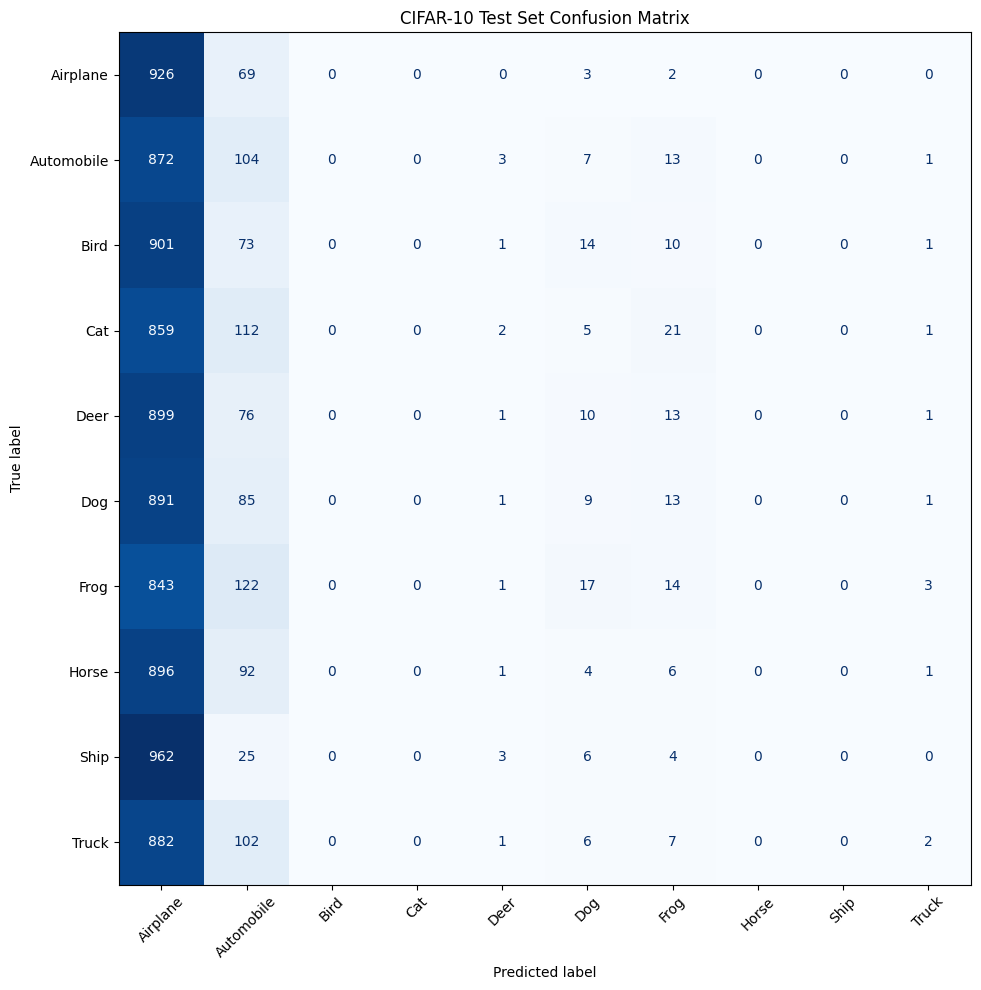

In [50]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# CIFAR-10 class names
class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("CIFAR-10 Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [51]:
import numpy as np

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

print("Per-class accuracy:")

for i, name in enumerate(class_names):
    class_total = np.sum(y_test == i)
    correct = np.sum((y_test == i) & (y_pred == i))
    accuracy = correct / class_total if class_total else 0

    print(f"{name}: {accuracy * 100:.2f}%")

Per-class accuracy:
Airplane: 92.60%
Automobile: 10.40%
Bird: 0.00%
Cat: 0.00%
Deer: 0.10%
Dog: 0.90%
Frog: 1.40%
Horse: 0.00%
Ship: 0.00%
Truck: 0.20%


In [52]:
from collections import Counter

print("Predicted class counts:")
for class_id, count in sorted(Counter(y_pred).items()):
    print(f"{class_id} ({class_names[class_id]}): {count}")

print("\nActual class counts:")
for class_id, count in sorted(Counter(y_test).items()):
    print(f"{class_id} ({class_names[class_id]}): {count}")

Predicted class counts:
0 (Airplane): 8931
1 (Automobile): 860
4 (Deer): 14
5 (Dog): 81
6 (Frog): 103
9 (Truck): 11

Actual class counts:
0 (Airplane): 1000
1 (Automobile): 1000
2 (Bird): 1000
3 (Cat): 1000
4 (Deer): 1000
5 (Dog): 1000
6 (Frog): 1000
7 (Horse): 1000
8 (Ship): 1000
9 (Truck): 1000


In [53]:
print("First 5 prediction probabilities:")
print(best_model.forward(x_test_flat[:5]))

print("\nPredicted class for first 5 images:")
print(np.argmax(best_model.forward(x_test_flat[:5]), axis=1))

First 5 prediction probabilities:
[[0.11527638 0.1080203  0.10104297 0.09766918 0.10023698 0.10345912
  0.10304319 0.08293171 0.09013995 0.09818024]
 [0.12822284 0.10997628 0.09207764 0.09601972 0.10550885 0.10845942
  0.10125152 0.07677881 0.0910192  0.09068572]
 [0.13233491 0.11108037 0.09728542 0.09567447 0.09716991 0.11240736
  0.10183483 0.07374681 0.08944783 0.08901809]
 [0.12453868 0.10917791 0.09703508 0.09573987 0.10520623 0.11496147
  0.10063966 0.07086905 0.08598729 0.09584476]
 [0.12187786 0.10313985 0.09621837 0.09887433 0.09957907 0.10979942
  0.10300872 0.08205586 0.08960557 0.09584096]]

Predicted class for first 5 images:
[0 0 0 0 0]


In [56]:
print("history_best exists:", "history_best" in globals())
print("best_model exists:", "best_model" in globals())

history_best exists: False
best_model exists: True


In [57]:
history_best = train_network(
    best_model,
    X_train_q4,
    y_train_q4,
    X_val,
    y_val,
    epochs=10,
    batch_size=64,
    learning_rate=0.0001,
    optimizer="nadam",
    weight_decay=0.0005
)

Epoch 1/10 - Loss: 2.0109 - Accuracy: 0.2598 - Val Loss: 1.8867 - Val Accuracy: 0.3168
Epoch 2/10 - Loss: 1.8049 - Accuracy: 0.3488 - Val Loss: 1.7634 - Val Accuracy: 0.3694
Epoch 3/10 - Loss: 1.7190 - Accuracy: 0.3833 - Val Loss: 1.7110 - Val Accuracy: 0.3870
Epoch 4/10 - Loss: 1.6612 - Accuracy: 0.4061 - Val Loss: 1.6608 - Val Accuracy: 0.4064
Epoch 5/10 - Loss: 1.6183 - Accuracy: 0.4207 - Val Loss: 1.5999 - Val Accuracy: 0.4294
Epoch 6/10 - Loss: 1.5830 - Accuracy: 0.4355 - Val Loss: 1.5898 - Val Accuracy: 0.4254
Epoch 7/10 - Loss: 1.5555 - Accuracy: 0.4455 - Val Loss: 1.5963 - Val Accuracy: 0.4226
Epoch 8/10 - Loss: 1.5328 - Accuracy: 0.4515 - Val Loss: 1.5689 - Val Accuracy: 0.4336
Epoch 9/10 - Loss: 1.5155 - Accuracy: 0.4585 - Val Loss: 1.5395 - Val Accuracy: 0.4468
Epoch 10/10 - Loss: 1.4987 - Accuracy: 0.4623 - Val Loss: 1.5378 - Val Accuracy: 0.4540


In [58]:
print("Training accuracy:", history_best["accuracy"])
print("Validation accuracy:", history_best["val_accuracy"])
print("Training loss:", history_best["loss"])
print("Validation loss:", history_best["val_loss"])

Training accuracy: [np.float64(0.25984444444444443), np.float64(0.34884444444444446), np.float64(0.38333333333333336), np.float64(0.4060888888888889), np.float64(0.4206666666666667), np.float64(0.43548888888888887), np.float64(0.44551111111111114), np.float64(0.45153333333333334), np.float64(0.4585111111111111), np.float64(0.4622888888888889)]
Validation accuracy: [np.float64(0.3168), np.float64(0.3694), np.float64(0.387), np.float64(0.4064), np.float64(0.4294), np.float64(0.4254), np.float64(0.4226), np.float64(0.4336), np.float64(0.4468), np.float64(0.454)]
Training loss: [np.float64(2.0109095243089765), np.float64(1.8048664610110634), np.float64(1.7190409567504494), np.float64(1.6612028647068897), np.float64(1.6182642947736345), np.float64(1.5830141432933034), np.float64(1.5554584116254717), np.float64(1.5327731181422937), np.float64(1.5155264385933827), np.float64(1.4987143993021879)]
Validation loss: [np.float64(1.88668458945861), np.float64(1.7634298680667457), np.float64(1.71095

In [59]:
# Generate fresh predictions after training
y_pred_probs = best_model.forward(x_test_flat)

y_pred = np.argmax(y_pred_probs, axis=1)

# Calculate test accuracy
from sklearn.metrics import accuracy_score

test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("Prediction counts:", np.bincount(y_pred, minlength=10))

Test Accuracy: 45.67%
Prediction counts: [1173 1184  867  457 1454  650 1260  773  979 1203]


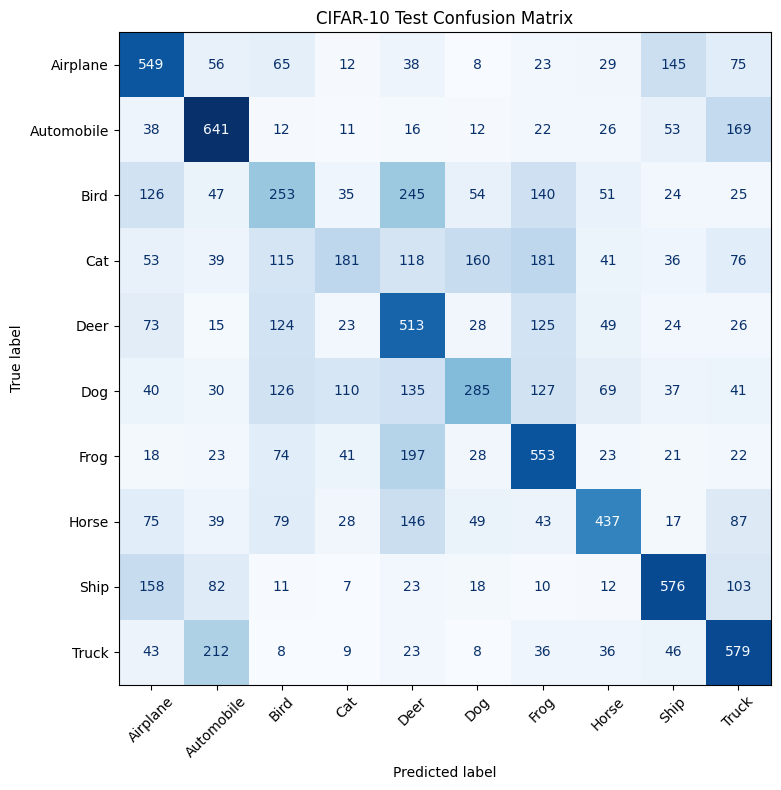

In [60]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("CIFAR-10 Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [61]:
from sklearn.metrics import classification_report

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

    Airplane       0.47      0.55      0.51      1000
  Automobile       0.54      0.64      0.59      1000
        Bird       0.29      0.25      0.27      1000
         Cat       0.40      0.18      0.25      1000
        Deer       0.35      0.51      0.42      1000
         Dog       0.44      0.28      0.35      1000
        Frog       0.44      0.55      0.49      1000
       Horse       0.57      0.44      0.49      1000
        Ship       0.59      0.58      0.58      1000
       Truck       0.48      0.58      0.53      1000

    accuracy                           0.46     10000
   macro avg       0.46      0.46      0.45     10000
weighted avg       0.46      0.46      0.45     10000



In [62]:
import numpy as np

def cross_entropy_loss(y_true, y_pred):
    epsilon = 1e-12
    y_pred = np.clip(y_pred, epsilon, 1.0)

    if y_true.ndim == 1:
        y_true = np.eye(10)[y_true]

    return -np.mean(np.sum(y_true * np.log(y_pred), axis=1))


def squared_error_loss(y_true, y_pred):
    if y_true.ndim == 1:
        y_true = np.eye(10)[y_true]

    return np.mean(np.sum((y_pred - y_true) ** 2, axis=1))


print("Cross-entropy and squared-error loss functions created!")

Cross-entropy and squared-error loss functions created!


In [63]:
def backward_mse(network, X, y):
    m = X.shape[0]

    activations = [X]
    A = X

    # Forward pass through hidden layers
    for i in range(len(network.weights) - 1):
        Z = np.dot(A, network.weights[i]) + network.biases[i]
        A = network.activation(Z)
        activations.append(A)

    # Output layer
    Z = np.dot(A, network.weights[-1]) + network.biases[-1]
    Y_hat = softmax(Z)
    activations.append(Y_hat)

    # One-hot encode labels
    y_one_hot = np.eye(10)[y.astype(int)]

    # MSE gradient at the softmax output
    dZ = (2 / m) * (Y_hat - y_one_hot)
    dZ = dZ * Y_hat * (1 - Y_hat)

    dW = [None] * len(network.weights)
    db = [None] * len(network.biases)

    for i in reversed(range(len(network.weights))):
        dW[i] = np.dot(activations[i].T, dZ)
        db[i] = np.sum(dZ, axis=0, keepdims=True)

        if i > 0:
            dA = np.dot(dZ, network.weights[i].T)
            Z_hidden = np.dot(
                activations[i - 1], network.weights[i - 1]
            ) + network.biases[i - 1]

            dZ = dA * network.activation_derivative(Z_hidden)

    return dW, db

In [65]:
# Test MSE backpropagation on a small batch
X_sample = X_train_q4[:8]
y_sample = y_train_q4[:8]

dW_mse, db_mse = backward_mse(best_model, X_sample, y_sample)

print("Number of weight gradients:", len(dW_mse))
print("Number of bias gradients:", len(db_mse))

for i in range(len(dW_mse)):
    print(f"Layer {i+1}: dW shape = {dW_mse[i].shape}, db shape = {db_mse[i].shape}")

print("MSE backpropagation test completed!")

Number of weight gradients: 6
Number of bias gradients: 6
Layer 1: dW shape = (3072, 64), db shape = (1, 64)
Layer 2: dW shape = (64, 64), db shape = (1, 64)
Layer 3: dW shape = (64, 64), db shape = (1, 64)
Layer 4: dW shape = (64, 64), db shape = (1, 64)
Layer 5: dW shape = (64, 64), db shape = (1, 64)
Layer 6: dW shape = (64, 10), db shape = (1, 10)
MSE backpropagation test completed!


In [66]:
# Compare cross-entropy and MSE loss on the same predictions

X_sample = X_val[:1000]
y_sample = y_val[:1000]

predictions = best_model.forward(X_sample)

# Convert labels to one-hot encoding
y_one_hot = np.eye(10)[y_sample.astype(int)]

# Cross-entropy loss
ce_loss = -np.mean(
    np.sum(y_one_hot * np.log(predictions + 1e-12), axis=1)
)

# Mean squared error loss
mse_loss = np.mean((predictions - y_one_hot) ** 2)

print("Cross-Entropy Loss:", ce_loss)
print("Mean Squared Error Loss:", mse_loss)

Cross-Entropy Loss: 1.5283876246590076
Mean Squared Error Loss: 0.06856336494172485


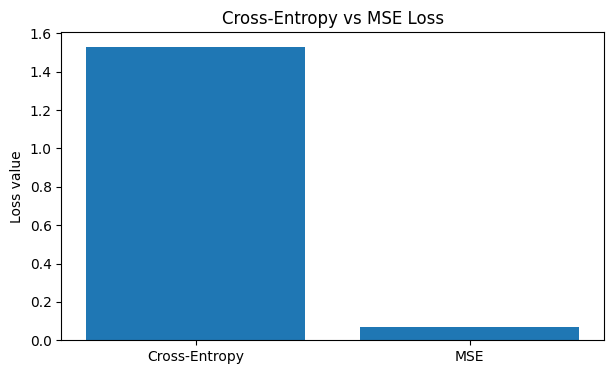

In [67]:
import matplotlib.pyplot as plt

# Compare losses using the same trained model's predictions
X_sample = X_val[:1000]
y_sample = y_val[:1000]

predictions = best_model.forward(X_sample)
y_one_hot = np.eye(10)[y_sample.astype(int)]

# Loss comparison
ce_loss = -np.mean(
    np.sum(y_one_hot * np.log(predictions + 1e-12), axis=1)
)
mse_loss = np.mean((predictions - y_one_hot) ** 2)

plt.figure(figsize=(7, 4))
plt.bar(
    ["Cross-Entropy", "MSE"],
    [ce_loss, mse_loss]
)
plt.ylabel("Loss value")
plt.title("Cross-Entropy vs MSE Loss")
plt.show()

In [68]:
# Calculate predictions on the validation set
X_sample = X_val[:1000]
y_sample = y_val[:1000]

predictions = best_model.forward(X_sample)
y_pred = np.argmax(predictions, axis=1)

accuracy = np.mean(y_pred == y_sample)

print("Validation Accuracy:", round(accuracy * 100, 2), "%")

Validation Accuracy: 45.9 %


In [69]:
# Create two models with the same architecture and initialization
np.random.seed(42)

ce_model = NeuralNetwork(
    input_size=3072,
    hidden_layers=[64, 64, 64, 64, 64],
    output_size=10,
    activation="relu",
    weight_init="xavier"
)

np.random.seed(42)

mse_model = NeuralNetwork(
    input_size=3072,
    hidden_layers=[64, 64, 64, 64, 64],
    output_size=10,
    activation="relu",
    weight_init="xavier"
)

print("Cross-entropy model created")
print("MSE model created")

Cross-entropy model created
MSE model created


In [70]:
def train_network_q8(
    network, X, y, X_val, y_val,
    loss_type="cross_entropy",
    epochs=5,
    batch_size=64,
    learning_rate=0.001
):
    history = {
        "loss": [],
        "val_loss": [],
        "accuracy": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):
        indices = np.random.permutation(len(X))
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for start in range(0, len(X), batch_size):
            xb = X_shuffled[start:start + batch_size]
            yb = y_shuffled[start:start + batch_size].astype(int)

            # Forward pass
            probabilities = network.forward(xb)
            y_one_hot = np.eye(10)[yb]

            # Calculate gradient for the selected loss
            if loss_type == "cross_entropy":
                dZ = (probabilities - y_one_hot) / len(xb)
            elif loss_type == "mse":
                dZ = (
                    2 * (probabilities - y_one_hot)
                    * probabilities
                    * (1 - probabilities)
                ) / len(xb)
            else:
                raise ValueError("Unknown loss_type")

            # Backpropagate using the loss gradient
            activations = [xb]
            A = xb

            for i in range(len(network.weights) - 1):
                Z = A @ network.weights[i] + network.biases[i]
                A = network.activation(Z)
                activations.append(A)

            for i in reversed(range(len(network.weights))):
                dW = activations[i].T @ dZ
                db = np.sum(dZ, axis=0, keepdims=True)

                if i > 0:
                    dA = dZ @ network.weights[i].T
                    Z_prev = (
                        activations[i - 1] @ network.weights[i - 1]
                        + network.biases[i - 1]
                    )
                    dZ = dA * network.activation_derivative(Z_prev)

                network.weights[i] -= learning_rate * dW
                network.biases[i] -= learning_rate * db

        # Evaluate after each epoch
        train_probs = network.forward(X)
        val_probs = network.forward(X_val)

        y_train_oh = np.eye(10)[y.astype(int)]
        y_val_oh = np.eye(10)[y_val.astype(int)]

        if loss_type == "cross_entropy":
            train_loss = -np.mean(
                np.sum(y_train_oh * np.log(train_probs + 1e-12), axis=1)
            )
            val_loss = -np.mean(
                np.sum(y_val_oh * np.log(val_probs + 1e-12), axis=1)
            )
        else:
            train_loss = np.mean((train_probs - y_train_oh) ** 2)
            val_loss = np.mean((val_probs - y_val_oh) ** 2)

        train_acc = np.mean(np.argmax(train_probs, axis=1) == y)
        val_acc = np.mean(np.argmax(val_probs, axis=1) == y_val)

        history["loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        print(
            f"{loss_type} | Epoch {epoch + 1}/{epochs} | "
            f"Loss: {train_loss:.4f} | "
            f"Validation accuracy: {val_acc:.4f}"
        )

    return history

In [71]:
history_ce = train_network_q8(
    ce_model,
    X_train_q4[:5000],
    y_train_q4[:5000],
    X_val[:1000],
    y_val[:1000],
    loss_type="cross_entropy",
    epochs=3,
    batch_size=64,
    learning_rate=0.001
)

print("\nCross-Entropy training completed!")

cross_entropy | Epoch 1/3 | Loss: 2.3073 | Validation accuracy: 0.0930
cross_entropy | Epoch 2/3 | Loss: 2.3002 | Validation accuracy: 0.0970
cross_entropy | Epoch 3/3 | Loss: 2.2955 | Validation accuracy: 0.1030

Cross-Entropy training completed!


In [72]:
history_mse = train_network_q8(
    mse_model,
    X_train_q4[:5000],
    y_train_q4[:5000],
    X_val[:1000],
    y_val[:1000],
    loss_type="mse",
    epochs=3,
    batch_size=64,
    learning_rate=0.001
)

print("\nMSE training completed!")

mse | Epoch 1/3 | Loss: 0.0903 | Validation accuracy: 0.0920
mse | Epoch 2/3 | Loss: 0.0903 | Validation accuracy: 0.0920
mse | Epoch 3/3 | Loss: 0.0902 | Validation accuracy: 0.0930

MSE training completed!


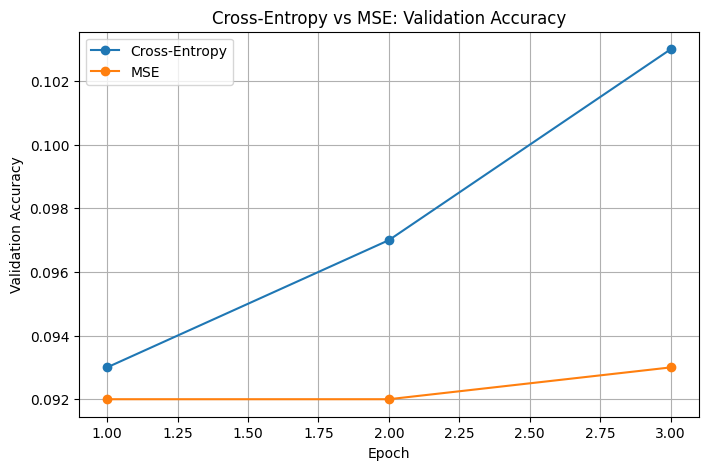

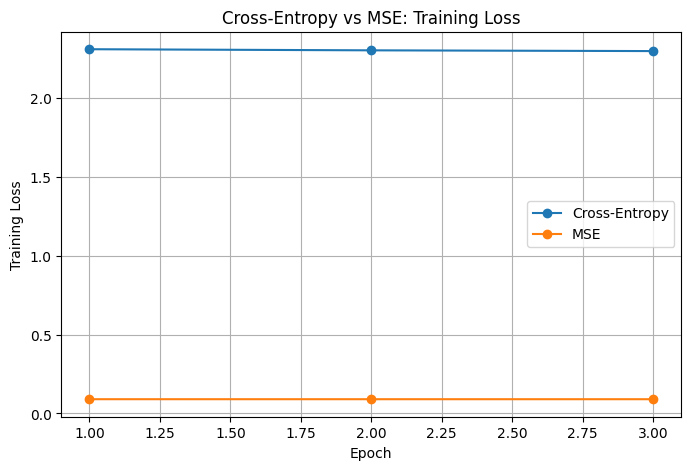

Cross-Entropy final validation accuracy: 10.3 %
MSE final validation accuracy: 9.3 %


In [73]:
import matplotlib.pyplot as plt

epochs = range(1, len(history_ce["val_accuracy"]) + 1)

# Validation accuracy comparison
plt.figure(figsize=(8, 5))
plt.plot(epochs, history_ce["val_accuracy"], marker="o",
         label="Cross-Entropy")
plt.plot(epochs, history_mse["val_accuracy"], marker="o",
         label="MSE")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Cross-Entropy vs MSE: Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Training loss comparison
plt.figure(figsize=(8, 5))
plt.plot(epochs, history_ce["loss"], marker="o",
         label="Cross-Entropy")
plt.plot(epochs, history_mse["loss"], marker="o",
         label="MSE")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Cross-Entropy vs MSE: Training Loss")
plt.legend()
plt.grid(True)
plt.show()

print("Cross-Entropy final validation accuracy:",
      round(history_ce["val_accuracy"][-1] * 100, 2), "%")

print("MSE final validation accuracy:",
      round(history_mse["val_accuracy"][-1] * 100, 2), "%")

### Q8 Conclusion

Cross-Entropy achieved 10.3% validation accuracy, while Mean Squared Error achieved 9.3% after three epochs. Cross-Entropy performed slightly better in this experiment. Both results are low, so further training and tuning are needed for a reliable comparison.